# Build a step as a graph: `eagle.Graph`

> Write a step once as nodes, let eagle work out what depends on what, then
> look at it, run it, and watch it refuse the mistakes that would otherwise
> race.

**Time:** ~8 min · **Runs on:** CPU (the same cells lower to a captured CUDA
graph when the planes are cupy arrays) · **You need:** eagle, hawk and NumPy; read first: {doc}`../quickstart_python`, {doc}`../graph_model`

You will end with a picture: a seed feeding two parallel branches that
join inside a conditional, drawn by eagle itself.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [ ]:
# Colab setup, generated by docs/_tools/nb_colab_setup.py (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk not found. Install with `pip install raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [1]:
import numpy as np
import eagle
from eagle.graph import opaque


## A graph from two launches

We start with real kernels. Two small [hawk](https://amasat01.github.io/hawk/)
kernels, built into plans and bound over arrays of our own: `y = a * x`, then
`z = y + 1`.

In [2]:
import tempfile
import hawk
from hawk import Mutable, Param, Scalar


@hawk.kernel
def scale(x: Scalar, a: Param, y: Mutable[Scalar]):
    y = a * x


@hawk.kernel
def shift(x: Scalar, y: Mutable[Scalar]):
    y = x + 1.0


scale_plan, shift_plan = eagle.deploy([scale, shift], targets=("host",),
                                      cache_dir=tempfile.mkdtemp())
x = np.arange(8.0)
y = np.zeros(8)
z = np.zeros(8)

g = eagle.Graph()
g.add(scale_plan.bind(x=x, a=2.0, y=y), name="scale")
g.add(shift_plan.bind(x=y, y=z), name="shift")
print(repr(g))

<eagle.Graph 2 nodes, 2 stages, unbuilt>


We never said that `shift` has to wait for `scale`. `shift` reads `y`, `scale`
writes it, and eagle sees that from the arrays themselves. Ask for the edges:

In [3]:
for edge in g.edges():
    print(edge)

Edge(src=0, dst=1, plane='y', kind='RAW')


One edge, `scale -> shift` on the plane `y`, a `RAW` (read-after-write)
dependency. Now look at the whole graph:

In [4]:
g.show()

eagle.Graph  2 nodes · 0 groups · backend: (not built)

  stage 0 ┌───────┐
          │ scale │
          └───┬───┘
              y
              │
  stage 1 ┌───┴───┐
          │ shift │
          └───────┘



`show()` works on the graph as it stands, before it is built. Build it, launch
it, and check the answer:

In [5]:
g.build().launch()
print("backend:", g.backend, "| schedule:", g.schedule)
print("z == 2x + 1:", bool(np.array_equal(z, 2 * x + 1)))
g.show()

backend: cpu | schedule: ('work_share', 'work_share')
z == 2x + 1: True
eagle.Graph  2 nodes · 0 groups · backend: cpu

  stage 0 work_share ┌───────┐
                     │ scale │
                     └───┬───┘
                         y
                         │
  stage 1 work_share ┌───┴───┐
                     │ shift │
                     └───────┘



After `build()` the picture also says how each stage runs: `work_share` is the
CPU lowering, `capture` is what a GPU build prints.

## Fork and join

Two independent pieces of work can share a stage. Here two opaque ops (any
callable you can run, with the arrays it touches *declared*) both read `base`
and write their own result; a third node combines them.

In [6]:
base = np.linspace(0.0, 1.0, 8)
left, right, total = np.zeros(8), np.zeros(8), np.zeros(8)

fork = eagle.Graph()
fork.add_group([
    opaque(lambda: np.square(base, out=left), reads={"base": base}, writes={"left": left}),
    opaque(lambda: np.sqrt(base, out=right), reads={"base": base}, writes={"right": right}),
], names=["square", "root"])
fork.add_node(opaque(lambda: np.add(left, right, out=total),
                     reads={"left": left, "right": right}, writes={"total": total}),
              name="combine")
fork.build().launch()
print(fork)

eagle.Graph  3 nodes · 1 group · backend: cpu

  stage 0 work_share ┌╌╌╌╌╌╌╌╌╌┐   ┌╌╌╌╌╌╌╌┐
                     ╎ square  ╎   ╎ root  ╎
                     └╌╌╌╌┬╌╌╌╌┘   └╌╌╌┬╌╌╌┘
                          left         right
                          └─────┬──────┘
  stage 1 work_share       ┌╌╌╌╌┴╌╌╌╌┐
                           ╎ combine ╎
                           └╌╌╌╌╌╌╌╌╌┘



Both branches sit on stage 0 and `combine` on stage 1: no edge between the
branches, an edge from each into `combine`. The branches only read `base`, so
sharing it is fine.

## What a conflict looks like

Now make the branches fight: both write the *same* array. On a GPU that is a
race; on the CPU it would silently depend on order. Either way eagle refuses it
at `build()`, naming both nodes and both planes.

In [7]:
shared = np.zeros(8)
racy = eagle.Graph().add_group([
    opaque(lambda: None, writes={"first_out": shared}),
    opaque(lambda: None, reads={"second_in": shared[2:]}),
], names=["first", "second"])
try:
    racy.build()
except ValueError as err:
    print(err)

eagle.Graph.build: 'first' (node 0) and 'second' (node 1) are siblings of one fork/join group but overlap (RAW): 'first' plane 'first_out' and 'second' plane 'second_in' share memory; give each branch its own plane, or order them in one branch


The check is about *bytes*, not names: `shared[2:]` is a different Python object
and a different name, but it overlaps. It is also stride-aware, so views that
only *look* close do not trip it:

In [8]:
evens_odds = eagle.Graph().add_group([
    opaque(lambda: None, writes={"even": shared[::2]}),
    opaque(lambda: None, writes={"odd": shared[1::2]}),
]).build()
print("interleaved halves of one array: fine, built on", evens_odds.backend)

interleaved halves of one array: fine, built on cpu


## Conditionals

A step that only sometimes runs is the `eagle.skippable` you already know. Give
it a node (so its planes are declared) and add it to the graph. A guard is a
count in an array: the step runs while it is non-zero. `eagle.repeat_while`
loops the same way, up to a cap.

In [9]:
field = np.zeros(4)
flag = np.array([1], dtype=np.uint32)        # non-zero: run
ticks = []


def refine():
    ticks.append(1)
    field[:] += 1.0
    flag[0] = 0                               # one pass is enough


guarded = (eagle.Graph()
           .add_node(opaque(lambda: field.fill(0.0), writes={"field": field}), name="reset")
           .add_node(eagle.skippable(opaque(refine, reads={"field": field}, writes={"field": field}),
                                     eagle.SkipGuard.nonzero(flag)), name="refine")
           .build())
guarded.launch()
print("refine ran", len(ticks), "time(s); field =", field)
guarded.launch()
print("flag is 0 now, so refine is skipped: still", len(ticks), "run; field =", field)
guarded.show()

refine ran 1 time(s); field = [1. 1. 1. 1.]
flag is 0 now, so refine is skipped: still 1 run; field = [0. 0. 0. 0.]
eagle.Graph  2 nodes · 0 groups · backend: cpu

  stage 0 work_share      ┌╌╌╌╌╌╌╌┐
                          ╎ reset ╎
                          └╌╌╌┬╌╌╌┘
                              field,fiel…
                              │
                     ╭─ skip if guard ─╮
  stage 1 work_share │ ┌╌╌╌╌╌╌┴╌╌╌╌╌╌┐ │
                     │ ╎   refine    ╎ │
                     │ └╌╌╌╌╌╌╌╌╌╌╌╌╌┘ │
                     ╰─────────────────╯



The frame is the conditional and carries its label. A loop prints as
`repeat ≤ N`. The guard is read *at launch*, never baked in at build, so the
second `launch()` skips the step without rebuilding anything.

## One graph, several threads

Distinct graphs run at once. One graph shared by two threads is for one caller
at a time, and the second is told so with `eagle.Busy` instead of being queued
or handed a half-run state. Here a slow node holds the graph while another
thread tries to launch it (and a third just *looks* at it, which never blocks):

In [10]:
import threading

entered, release = threading.Event(), threading.Event()


def slow():
    entered.set()
    release.wait(10)


shared_graph = eagle.Graph().add_node(opaque(slow, writes={"s": np.zeros(1)}), name="slow").build()
worker = threading.Thread(target=shared_graph.launch)
worker.start()
entered.wait(10)
try:
    shared_graph.launch()
except eagle.Busy as err:
    print("second caller:", err)
print("looking never blocks:", repr(shared_graph))
release.set()
worker.join()

second caller: eagle.Graph.launch: another call is still running on this Graph; give each thread its own Graph, or wait for it
looking never blocks: <eagle.Graph 1 nodes, 1 stages, cpu>


## Seeing it

`g.show()` is the text picture; `str(g)` returns the same text. For a figure,
`g.plot()` returns a matplotlib `Figure` (install it with
`pip install "raptor-eagle[plot]"`); for docs and tools there is Mermaid and
Graphviz. All of them come from one layout, so they always agree.

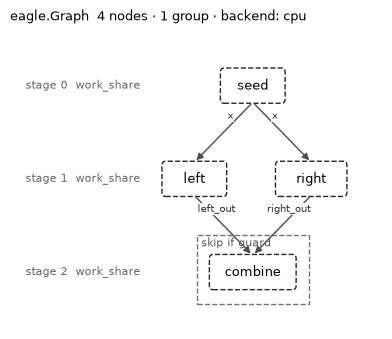

In [11]:
seed, a, b, out = (np.zeros(8) for _ in range(4))
flag2 = np.ones(1, dtype=np.uint32)
nop = lambda: None

pretty = eagle.Graph()
pretty.add_node(opaque(nop, writes={"x": seed}), name="seed")
pretty.add_group([opaque(nop, reads={"x": seed}, writes={"left_out": a}),
                  opaque(nop, reads={"x": seed}, writes={"right_out": b})],
                 names=["left", "right"])
pretty.add_node(eagle.skippable(
    opaque(nop, reads={"left_out": a, "right_out": b}, writes={"out": out}),
    eagle.SkipGuard.nonzero(flag2)), name="combine")
pretty.build()

import io
from IPython.display import Image

fig = pretty.plot()                      # a plain matplotlib Figure
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100, bbox_inches="tight")
Image(buf.getvalue())

In [12]:
print(pretty.to_mermaid())

flowchart TD
  n0["seed<br/>work_share"]
  n1["left<br/>work_share"]
  n2["right<br/>work_share"]
  subgraph f0["skip if guard"]
    n3["combine<br/>work_share"]
  end
  n0 -->|"x"| n1
  n0 -->|"x"| n2
  n1 -->|"left_out"| n3
  n2 -->|"right_out"| n3
  classDef opaque stroke-dasharray: 4 2
  class n0,n1,n2,n3 opaque



## What just happened

- You never declared an edge. `eagle.Graph` read which arrays each node
  touches (on your own arrays, stride-aware) and derived `RAW`/`WAR`/`WAW`
  edges, so adding a node cannot silently break an ordering.
- A fork/join group put independent branches on one stage, and a branch that
  would race with its sibling was refused at `build()`, on every backend.
- `eagle.skippable` and `eagle.repeat_while` went in unchanged; the guard is
  read at launch, so one build serves every run.
- One graph, one caller at a time: a second thread gets `eagle.Busy`, naming
  the method in flight, while *looking* at the graph takes no guard.
- `show()`, `plot()`, `to_mermaid()` and `to_dot()` all draw the same layout,
  built so far, without building or launching anything.

## Try this

- Hand `fork` cupy arrays instead of numpy ones (and `cp.square` for the ops):
  `build()` infers the GPU, `fork.schedule` becomes `("capture", ...)`, and the
  group is captured as parallel siblings.
- Add `fork.edges()` to a cell: the three edges, and no edge between the
  branches.
- Make `racy` legal by giving each branch its own array.

## Next

{doc}`../graph_model` is the reference for everything used here.
{doc}`../graph_view` shows the same engine drawing a C++ graph.